# CSE 4309: Fraud Detection Live Demo
**Team:** Sagar Khadka, Bipin Adhikari, Bardan Karki, Samiksha Rijal, Samin Rijal.

This notebook has been executed with the included saved models. Run all cells for a fast offline demonstration. Slow training happens beforehand. The three cases illustrate a correct detection, a false alert, and missed fraud. They are deliberately selected, not a random evaluation sample.


In [1]:
from pathlib import Path
import sys, json, inspect, time
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
assert (root / 'source/demo.py').exists(), 'Run from the repository root'
sys.path.insert(0, str(root / 'source'))
import run_analysis
from demo import predict_cases
summary = json.loads((root / 'results/summary.json').read_text())
print('Three saved models loaded from this project. No full dataset download needed.')


Three saved models loaded from this project. No full dataset download needed.


## 1. Data quality and partitions

,Measure,Value
0,Raw rows,284807
1,Cleaned rows,283726
2,Fraud after cleaning,473
3,Exact duplicates removed,1081
4,Missing values,0


,split,rows,legitimate,fraud
0,train,170235,169951,284
1,validation,56745,56651,94
2,test,56746,56651,95


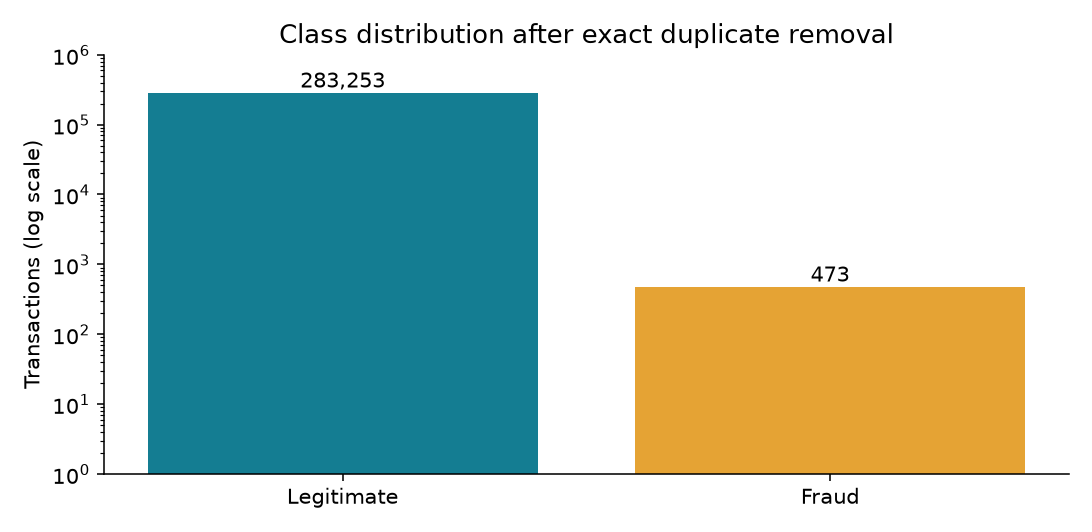

In [2]:
display(pd.DataFrame({
    'Measure':['Raw rows','Cleaned rows','Fraud after cleaning','Exact duplicates removed','Missing values'],
    'Value':[summary[k] for k in ['raw_rows','cleaned_rows','cleaned_fraud','duplicates_removed','missing_values']]
}))
display(pd.read_csv(root / 'results/splits.csv'))
display(Image(filename=str(root / 'figures/class_distribution.png'), width=650))


## 2. Actual preprocessing and model code
These excerpts are read directly from the implementation, not pseudocode. Explain removing duplicate rows before the split, stratification, and why the scaler is inside the Logistic Regression pipeline.


In [3]:
source = inspect.getsource(run_analysis.main)
start = source.index('    duplicate_count =')
end = source.index('    splits = []')
print(source[start:end])
print(inspect.getsource(run_analysis.make_estimator))


    duplicate_count = int(raw.duplicated().sum())
    # Exact rows can otherwise appear in different splits. Keep their first occurrence.
    data = raw.drop_duplicates().copy()
    data.index.name = 'source_row'
    X, y = data.drop(columns='Class'), data.Class
    trainval_idx, test_idx = train_test_split(data.index, test_size=.2,
        random_state=SEED, stratify=y)
    train_idx, val_idx = train_test_split(trainval_idx, test_size=.25,
        random_state=SEED, stratify=y.loc[trainval_idx])
    assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
    Xtr, Xv, Xt = X.loc[train_idx], X.loc[val_idx], X.loc[test_idx]
    ytr, yv, yt = y.loc[train_idx], y.loc[val_idx], y.loc[test_idx]

def make_estimator(name, weight=None):
    """One definition shared by the full experiment and saved-model preparation."""
    if name == 'Logistic Regression':
        return make_pipeline(StandardScaler(), LogisticRegression(C=1.0,
            so

## 3. Training and selection were completed before class
The saved models were fitted only on training rows. Weighting was selected by validation AP, thresholds by validation F1, and the family recommendation by selected validation F1. No test-driven tuning occurs here.


In [4]:
display(pd.read_csv(root / 'results/validation_candidates.csv', keep_default_na=False)
        [['model','class_weight','average_precision','f1','threshold']])
print('Model recommendation:', summary['recommended_model'])
print(inspect.getsource(run_analysis.threshold_for_f1))


,model,class_weight,average_precision,f1,threshold
0,Logistic Regression,None,0.802300,0.797872,0.116944
1,Logistic Regression,balanced,0.787617,0.846154,1.000000
2,Decision Tree,None,0.830531,0.827586,0.800000
3,Decision Tree,balanced,0.476392,0.679070,0.999268
4,Random Forest,None,0.877977,0.886486,0.349667
5,Random Forest,balanced,0.867146,0.875676,0.512322


Model recommendation: Random Forest
def threshold_for_f1(y, scores):
    precision, recall, thresholds = precision_recall_curve(y, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)
    # Deterministic tie rule: highest threshold among equal maximum F1 values.
    index = np.flatnonzero(np.isclose(f1, f1.max(), rtol=0, atol=1e-12))[-1]
    return float(thresholds[index])



## 4. Run three real test cases live
Class 1 means fraud. The score is compared against a frozen validation threshold. Scores are not calibrated confidence. The `case_type` column describes Random Forest's error category; other algorithms can behave differently.


In [5]:
cases = pd.read_csv(root / 'results/demo_cases.csv')
display(cases[['source_row','case_type','Time','Amount','Class']])
started = time.perf_counter()
live = predict_cases(root)
display(live.round({'score':6,'threshold':6}))
print(f'Live inference completed in {time.perf_counter()-started:.3f} seconds.')


,source_row,case_type,Time,Amount,Class
0,541,true_positive,406.0,0.00,1.0
1,8625,false_positive,11641.0,1.00,0.0
2,4920,false_negative,4462.0,239.93,1.0


,source_row,case_type,actual,model,score,threshold,prediction,correct
0,541,true_positive,1,Logistic Regression,0.252419,0.116944,1,True
1,8625,false_positive,0,Logistic Regression,0.088063,0.116944,0,True
2,4920,false_negative,1,Logistic Regression,0.002227,0.116944,0,False
3,541,true_positive,1,Decision Tree,1.000000,0.800000,1,True
4,8625,false_positive,0,Decision Tree,0.272727,0.800000,0,True
5,4920,false_negative,1,Decision Tree,0.263158,0.800000,0,False
6,541,true_positive,1,Random Forest,0.550616,0.349667,1,True
7,8625,false_positive,0,Random Forest,0.378123,0.349667,1,False
8,4920,false_negative,1,Random Forest,0.332012,0.349667,0,False


Live inference completed in 0.123 seconds.


### Interpretation
- Row 541 is fraud and all three models flag it.
- Row 8625 is legitimate. Random Forest raises a false alert while the other two models classify it correctly.
- Row 4920 is fraud and all three models miss it. Its forest score is just below the selected threshold.

Do not lower the threshold to fix this test example: that would tune on the test data. Changing a threshold requires a separate validation decision.


## 5. Recompute full test metrics from recorded predictions

,model,accuracy,precision,recall,f1,average_precision,roc_auc,tn,fp,fn,tp
0,Logistic Regression,0.999277,0.829268,0.715789,0.768362,0.694982,0.950266,56637,14,27,68
1,Decision Tree,0.999366,0.927536,0.673684,0.780488,0.711892,0.917390,56646,5,31,64
2,Random Forest,0.999454,0.910256,0.747368,0.820809,0.799054,0.963479,56644,7,24,71


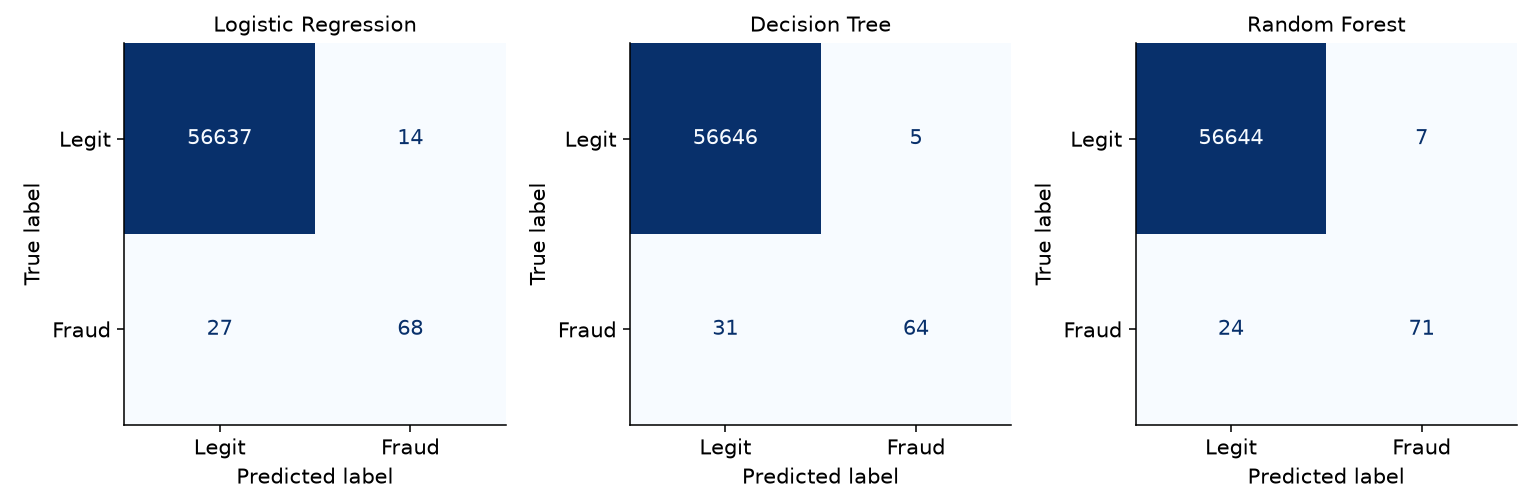

In [6]:
predictions = pd.read_csv(root / 'results/test_predictions.csv')
verified = []
for selected in summary['selected']:
    name = selected['model']
    metrics = run_analysis.evaluate(predictions.actual, predictions[name+'_score'], selected['threshold'])
    verified.append({'model':name, **metrics})
display(pd.DataFrame(verified)[['model','accuracy','precision','recall','f1','average_precision','roc_auc','tn','fp','fn','tp']])
display(Image(filename=str(root / 'figures/confusion_matrices.png'), width=1000))


## 6. Explain the evaluation code and limits

In [7]:
print(inspect.getsource(run_analysis.evaluate))
display(pd.read_csv(root / 'results/test_default_threshold.csv')[['model','threshold','precision','recall','f1']])


def evaluate(y, scores, threshold):
    pred = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(threshold=float(threshold), accuracy=float(accuracy_score(y, pred)),
        precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)),
        f1=float(f1_score(y, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y, scores)),
        average_precision=float(average_precision_score(y, scores)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))



,model,threshold,precision,recall,f1
0,Logistic Regression,0.5,0.848485,0.589474,0.695652
1,Decision Tree,0.5,0.866667,0.684211,0.764706
2,Random Forest,0.5,0.958333,0.726316,0.826347


Random Forest detects 71 of 95 fraud cases with 7 false alerts at the selected threshold. Its approximate 95% recall interval is 65.2%-82.4%. At threshold 0.5 its test F1 is slightly higher, but we retain the validation-selected threshold. A random split of one historical dataset does not establish future deployment performance.

**Before class:** test this notebook on your laptop, keep all files and packages locally available, and review `DEMO_GUIDE.md`. Actual personal contributions must be confirmed in `CONTRIBUTIONS.md`.

**Sources:** [Original dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), [TensorFlow mirror documentation](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data), [scikit-learn threshold guide](https://scikit-learn.org/stable/modules/classification_threshold.html). Analysis evidence: the repository's `results/` and `source/` folders.
